<a href="https://colab.research.google.com/github/sol-lapietra/Sequence-Alignment-Analysys/blob/main/notebooks/01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !git clone https://github.com/santidrelew/tp-mpg.git
    %cd tp-mpg

fatal: destination path 'tp-mpg' already exists and is not an empty directory.
/content/tp-mpg/tp-mpg


In [29]:
# Importamos todas las librerías necesarias
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import statsmodels.formula.api as smf
import math
from scipy import stats

# **1 - Exploración de los datos del dataset AirBnB Milan**

## **1.1 - CARGA DEL DATASET**

In [30]:
RAW_DATA_PATH = kagglehub.dataset_download("antoniokaggle/milan-airbnb-open-data-only-entire-apartments")

print("Path to dataset files:", RAW_DATA_PATH)

Using Colab cache for faster access to the 'milan-airbnb-open-data-only-entire-apartments' dataset.
Path to dataset files: /kaggle/input/milan-airbnb-open-data-only-entire-apartments


In [31]:
df_raw = pd.read_csv(Path(RAW_DATA_PATH) / "Airbnb_Milan.csv", index_col=0)
pd.set_option('display.max_columns', len(df_raw.columns)) # Para ver todas las columnas
pd.set_option('display.max_rows', 100)
df_raw

,id,host_id,host_location,host_response_time,host_response_rate,host_is_superhost,host_total_listings_count,host_has_profile_pic,host_identity_verified,neighbourhood_cleansed,zipcode,latitude,longitude,room_type,accommodates,bathrooms,bedrooms,beds,bed_type,daily_price,security_deposit,cleaning_fee,guests_included,extra_people,minimum_nights,availability_30,availability_60,availability_90,availability_365,number_of_reviews,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,TV,WiFi,Air_Condition,Wheelchair_accessible,Kitchen,Breakfast,Elevator,Heating,Washer,Iron,Host_greets_you,Paid_parking_on_premises,Luggage_dropoff_allowed,Long_term_stays_allowed,Doorman,Pets_allowed,Smoking_allowed,Suitable_for_events,24_hour_check_in
1,73892,387110,1,1,57,0,3,1,1,1,20121,45.47015,9.19134,Entire home/apt,2,3,1,1,1,94,1,45,1,0,2,29,59,89,364,84,94,9,9,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
2,74169,268127,1,1,57,0,1,1,0,1,20121,45.47169,9.18412,Entire home/apt,4,3,1,1,1,125,31,30,1,0,2,0,0,9,284,3,100,10,10,10,10,10,9,0,0,0,0,1,1,1,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,0
3,77958,387110,1,1,57,0,3,1,1,1,20121,45.47117,9.19135,Entire home/apt,2,3,1,1,1,100,1,45,1,0,2,29,59,89,364,70,97,9,10,10,10,10,9,0,1,1,1,1,1,1,0,1,0,1,1,0,1,0,0,0,0,0,0,0,1,0
4,93025,499743,1,1,57,0,1,1,0,1,20121,45.47204,9.19640,Entire home/apt,3,3,1,2,1,120,48,57,2,40,2,10,40,70,160,57,97,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,1,1,0,1,0,1,1,0,0,1,0,0,0
5,132705,391011,1,1,57,1,2,1,0,1,20135,45.45934,9.20609,Entire home/apt,2,3,0,1,3,70,13,45,1,0,30,27,57,87,362,44,90,9,9,10,10,9,9,0,1,1,1,1,1,1,0,1,0,1,1,1,1,1,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9318,35954783,56584596,1,1,57,0,1,1,1,9,20124,45.48586,9.19706,Entire home/apt,2,3,1,1,1,80,1,1,1,0,1,1,1,1,1,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,0,0,0,0
9319,36023503,271013325,1,1,57,0,1,1,0,9,20124,45.48170,9.18968,Entire home/apt,6,5,2,2,1,900,1,69,2,30,1,9,9,18,204,2,100,10,10,10,10,10,10,1,0,0,0,1,1,1,0,1,1,1,1,1,1,0,0,0,0,0,1,0,0,0
9320,36071908,271354203,1,0,57,0,1,1,0,9,20159,45.49807,9.18476,Entire home/apt,2,3,1,1,1,70,1,20,1,20,1,30,60,90,365,3,100,9,10,10,10,9,10,0,1,0,0,1,1,1,0,1,1,0,1,1,0,1,0,0,0,0,0,0,0,0
9321,36305676,171239896,1,1,40,0,3,1,0,9,20158,45.50107,9.18210,Entire home/apt,4,3,1,2,1,65,1,1,1,0,1,29,59,89,364,1,100,10,10,10,10,10,10,0,1,0,0,1,1,1,0,1,0,0,1,1,1,0,0,0,0,0,0,0,0,0


In [32]:
# Ponemos nuestra columna target daily_price al final
col_target = df_raw.pop("daily_price")
df_raw.insert(len(df_raw.columns), col_target.name, col_target)

## **1.2 - LIMPIEZA DE DATOS**

### DETECCION DE DATOS FALTANTES Y DUPLICADOS

In [33]:
# Verificamos si hay valores nulos en el DataFrame
sum(df_raw.isnull().sum())

0

No nulos en ninguna columna

Chequeamos si hay duplicados: nos fijamos por el `id`

In [34]:
es_unico = df_raw['id'].is_unique
print(f"¿La columna 'id' es clave unica?: {es_unico}")

ids_duplicados = df_raw['id'].duplicated().sum()
print(f"Cantidad de IDs repetidos: {ids_duplicados}")

¿La columna 'id' es clave unica?: True
Cantidad de IDs repetidos: 0


In [35]:
# Verificamos que ningun ID se repita
es_id_unico = df_raw["id"].is_unique
cant_ids_duplicados = df_raw["id"].duplicated().sum()

print("--- 1. VERIFICACIÓN DE CLAVES TÉCNICAS ---")
print(f"¿La columna 'id' es clave única a nivel base de datos?: {es_id_unico}")
print(f"Cantidad de IDs repetidos: {cant_ids_duplicados}")

# Buscamos que no hayan dos celdas exactamente iguales con distinto ID
cols_sin_id = [col for col in df_raw.columns if col not in ["id", "host_id"]]
duplicados_atributos_completos = df_raw.duplicated(
    subset=cols_sin_id, keep=False
).sum()

# Verificamos que la misma propiedad no este publicada bajo distinto ID
# Definimos atributos físicos y de ubicación exacta:
clave_negocio = [
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "beds",
    "daily_price",
]
duplicados_negocio = df_raw.duplicated(subset=clave_negocio, keep=False).sum()

print(
    f"Registros con todos los atributos identicos (salvo ID):"
    f" {duplicados_atributos_completos}"
)
print(
    f"Registros que comparten ubicacion exacta y caracteristicas clave:"
    f" {duplicados_negocio}"
)

--- 1. VERIFICACIÓN DE CLAVES TÉCNICAS ---
¿La columna 'id' es clave única a nivel base de datos?: True
Cantidad de IDs repetidos: 0
Registros con todos los atributos identicos (salvo ID): 0
Registros que comparten ubicacion exacta y caracteristicas clave: 0


Por lo tanto, confirmamos que no hay ningun tipo de dato duplicado.

### DETECCION DE VARIABLES CATEGORICAS

In [36]:
cols_categoricas = [
    col
    for col in df_raw.columns
    if set(df_raw[col].dropna().unique()).issubset({0, 1})
]
cols_continuas = [col for col in df_raw.columns if col not in cols_categoricas]

print(f"Total de columnas en el dataset: {df_raw.shape[1]}")
print(f"Variables categoricas identificadas ({len(cols_categoricas)}): {cols_categoricas}\n")
print(
    f"Variables continuas identificadas ({len(cols_continuas)}):"
    f" {cols_continuas}\n"
)

Total de columnas en el dataset: 60
Variables categoricas identificadas (28): ['host_location', 'host_response_time', 'host_is_superhost', 'host_has_profile_pic', 'host_identity_verified', 'instant_bookable', 'cancellation_policy', 'require_guest_profile_picture', 'require_guest_phone_verification', 'TV', 'WiFi', 'Air_Condition', 'Wheelchair_accessible', 'Kitchen', 'Breakfast', 'Elevator', 'Heating', 'Washer', 'Iron', 'Host_greets_you', 'Paid_parking_on_premises', 'Luggage_dropoff_allowed', 'Long_term_stays_allowed', 'Doorman', 'Pets_allowed', 'Smoking_allowed', 'Suitable_for_events', '24_hour_check_in']

Variables continuas identificadas (32): ['id', 'host_id', 'host_response_rate', 'host_total_listings_count', 'neighbourhood_cleansed', 'zipcode', 'latitude', 'longitude', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'bed_type', 'security_deposit', 'cleaning_fee', 'guests_included', 'extra_people', 'minimum_nights', 'availability_30', 'availability_60', 'availability_9

Sin embargo, 'neighbourhood_cleansed' y 'bed_type' son variables categoricas, asi que modificamos la lista manualmente

In [37]:
cols_a_mover = ["neighbourhood_cleansed", "bed_type"]

cols_continuas = [col for col in cols_continuas if col not in cols_a_mover]

## 1.3 - **Descripción del dataset: Milan Airbnb y Selección de Features**

El dataset contiene información sobre alojamientos publicados en Airbnb en la ciudad de Milán (Italia), considerando únicamente propiedades que se alquilan completas.

El objetivo del problema de regresión es **predecir el precio por noche (`daily_price`)** a partir de las características de los alojamientos, sus anfitriones, ubicación, disponibilidad y evaluaciones.




### ANALISIS DESCRIPTIVO DE VARIABLES CATEGORICAS

In [38]:
tabla_analisis_categoricas = (
    pd.DataFrame({
        "Proporcion 0 (%)": (df_raw[cols_categoricas] == 0).mean() * 100,
        "Proporcion 1 (%)": (df_raw[cols_categoricas] == 1).mean() * 100,
    })
    .round(2)
    .sort_values(by="Proporcion 1 (%)", ascending=False)
)

print("--- ANALISIS DESCRIPTIVO DE VARIABLES CATEGORICAS ---")
display(tabla_analisis_categoricas)

--- ANALISIS DESCRIPTIVO DE VARIABLES CATEGORICAS ---


,Proporcion 0 (%),Proporcion 1 (%)
host_has_profile_pic,0.04,99.96
Heating,1.93,98.07
Kitchen,3.27,96.73
host_location,4.04,95.96
WiFi,7.14,92.86
TV,12.75,87.25
host_response_time,13.08,86.92
cancellation_policy,14.25,85.75
Iron,18.79,81.21
Washer,18.97,81.03


Desde este analisis, eliminaremos las siguientes variables de nuestro modelo dada su poca varianza (< 5% en la clase minoritaria)
* host_has_profile_pic
* heating
* bed_type
* kitchen
* host_location
* require_guest_profile_picture
* require_guest_phone_verification
* suitable_for_events
* wheelchair_accesible


Ademas, hemos decidido eliminar tambien las siguientes variables:

* WiFi
* Tv

Son amenidades estándar que hoy en día se consideran commodities (casi obligatorias).

* host_response_time

No fija el precio del alquiler; es una métrica de soporte de la plataforma.

### ANALISIS DESCRIPTIVO DE VARIABLES CONTINUAS

Solo vamos a analizar variables cuantitativas continuas/discretas. Vamos a excluir coordenadas fijas de la propiedad, columnas relacionadas a reviews (ya que se encuentran siempre dentro de un rango fijo) y columnas de disponibilidad diaria (tambien tienen un rango acotado).

In [39]:
cols_excluir = ["latitude", "longitude", "log_daily_price", "id", "host_id", "zipcode", "host_response_rate",
                "review_scores_checkin", "review_scores_communication", "review_scores_accuracy", "review_scores_location",
                "review_scores_cleanliness", "review_scores_value", "review_scores_rating",
                "availability_30", "availability_60", "availability_90", "availability_365"]
cols_outliers = [
    col
    for col in cols_continuas
    if col not in cols_excluir and pd.api.types.is_numeric_dtype(df_raw[col])
]

In [40]:
reporte_outliers = []

for col in cols_outliers:
  serie = df_raw[col].dropna()

  # Z-score
  z = np.abs(stats.zscore(serie))
  n_z = (z > 3).sum()

  # Tukey IQR
  q1 = serie.quantile(0.25)
  q3 = serie.quantile(0.75)
  iqr = q3 - q1
  lim_inf = q1 - 1.5 * iqr
  lim_sup = q3 + 1.5 * iqr
  n_iqr = ((serie < lim_inf) | (serie > lim_sup)).sum()

  reporte_outliers.append({
      "Variable": col,
      "Mín": round(serie.min(), 2),
      "Q1": round(q1, 2),
      "Mediana": round(serie.median(), 2),
      "Q3": round(q3, 2),
      "Máx": round(serie.max(), 2),
      "Outliers (|Z|>3)": n_z,
      "% Outliers (Z)": round((n_z / len(serie)) * 100, 2),
      "Outliers (IQR)": n_iqr,
      "% Outliers (IQR)": round((n_iqr / len(serie)) * 100, 2),
  })

  df_tabla_outliers = pd.DataFrame(reporte_outliers).sort_values(
    by="% Outliers (IQR)", ascending=False
)

display(df_tabla_outliers.reset_index(drop=True))

,Variable,Mín,Q1,Mediana,Q3,Máx,Outliers (|Z|>3),% Outliers (Z),Outliers (IQR),% Outliers (IQR)
0,host_total_listings_count,0,1.0,2.0,7.0,847,183,1.96,1605,17.22
1,bathrooms,1,3.0,3.0,3.0,17,148,1.59,1459,15.65
2,number_of_reviews,1,4.0,14.0,44.0,791,234,2.51,982,10.53
3,daily_price,10,59.0,75.0,107.0,3000,86,0.92,885,9.49
4,minimum_nights,1,1.0,2.0,2.0,365,35,0.38,874,9.38
5,guests_included,1,1.0,2.0,2.0,18,124,1.33,565,6.06
6,cleaning_fee,1,30.0,45.0,57.0,108,0,0.00,216,2.32
7,accommodates,1,2.0,4.0,4.0,16,89,0.95,198,2.12
8,security_deposit,1,1.0,1.0,48.0,143,182,1.95,188,2.02
9,bedrooms,0,1.0,1.0,2.0,10,106,1.14,106,1.14


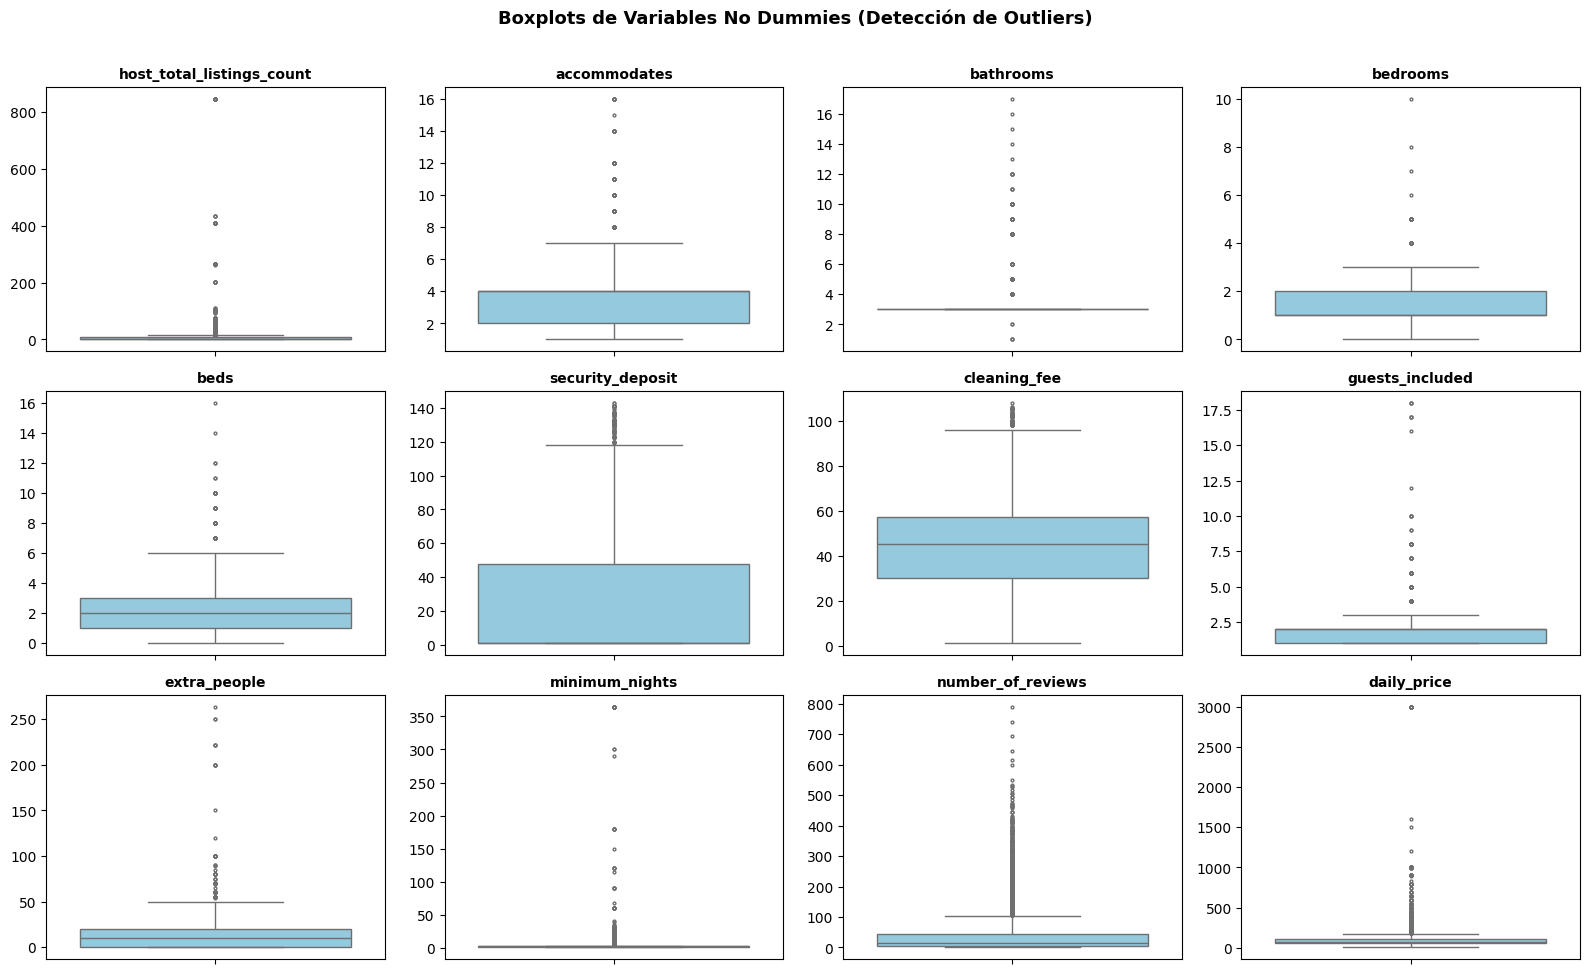

In [41]:
n_vars = len(cols_outliers)
n_cols = 4
n_rows = math.ceil(n_vars / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.2))
axes = axes.flatten()

for i, col in enumerate(cols_outliers):
  sns.boxplot(y=df_raw[col], ax=axes[i], color="skyblue", fliersize=2)
  axes[i].set_title(col, fontsize=10, fontweight="bold")
  axes[i].set_ylabel("")

# Ocultar subplots vacíos si sobran
for j in range(n_vars, len(axes)):
  fig.delaxes(axes[j])

plt.suptitle(
    "Boxplots de Variables No Dummies (Detección de Outliers)",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)
plt.tight_layout()
plt.show()

Todas las 12 variables analizadas presentan outliers analiticos o graficos, salvo excepciones puntuales:
* En los boxplots: Las 12 variables muestran puntos individuales por fuera de los bigotes superiores.
* En el metodo Tukey: Todas superan el corte.
* En el metodo $Z$-Score: 11 de las 12 variables tienen registros que se alejan a mas de 3 desvios estandar de la media. La unica que no presenta outliers bajo este criterio es cleaning_fee (0%).  

**ENTONCES, NUESTRAS VARIABLES QUEDAN:**


### 0) Target: precio diario

In [42]:
df_raw["daily_price"].describe()

,daily_price
count,9322.000000
mean,103.735143
std,137.956457
min,10.000000
25%,59.000000
50%,75.000000
75%,107.000000
max,3000.000000


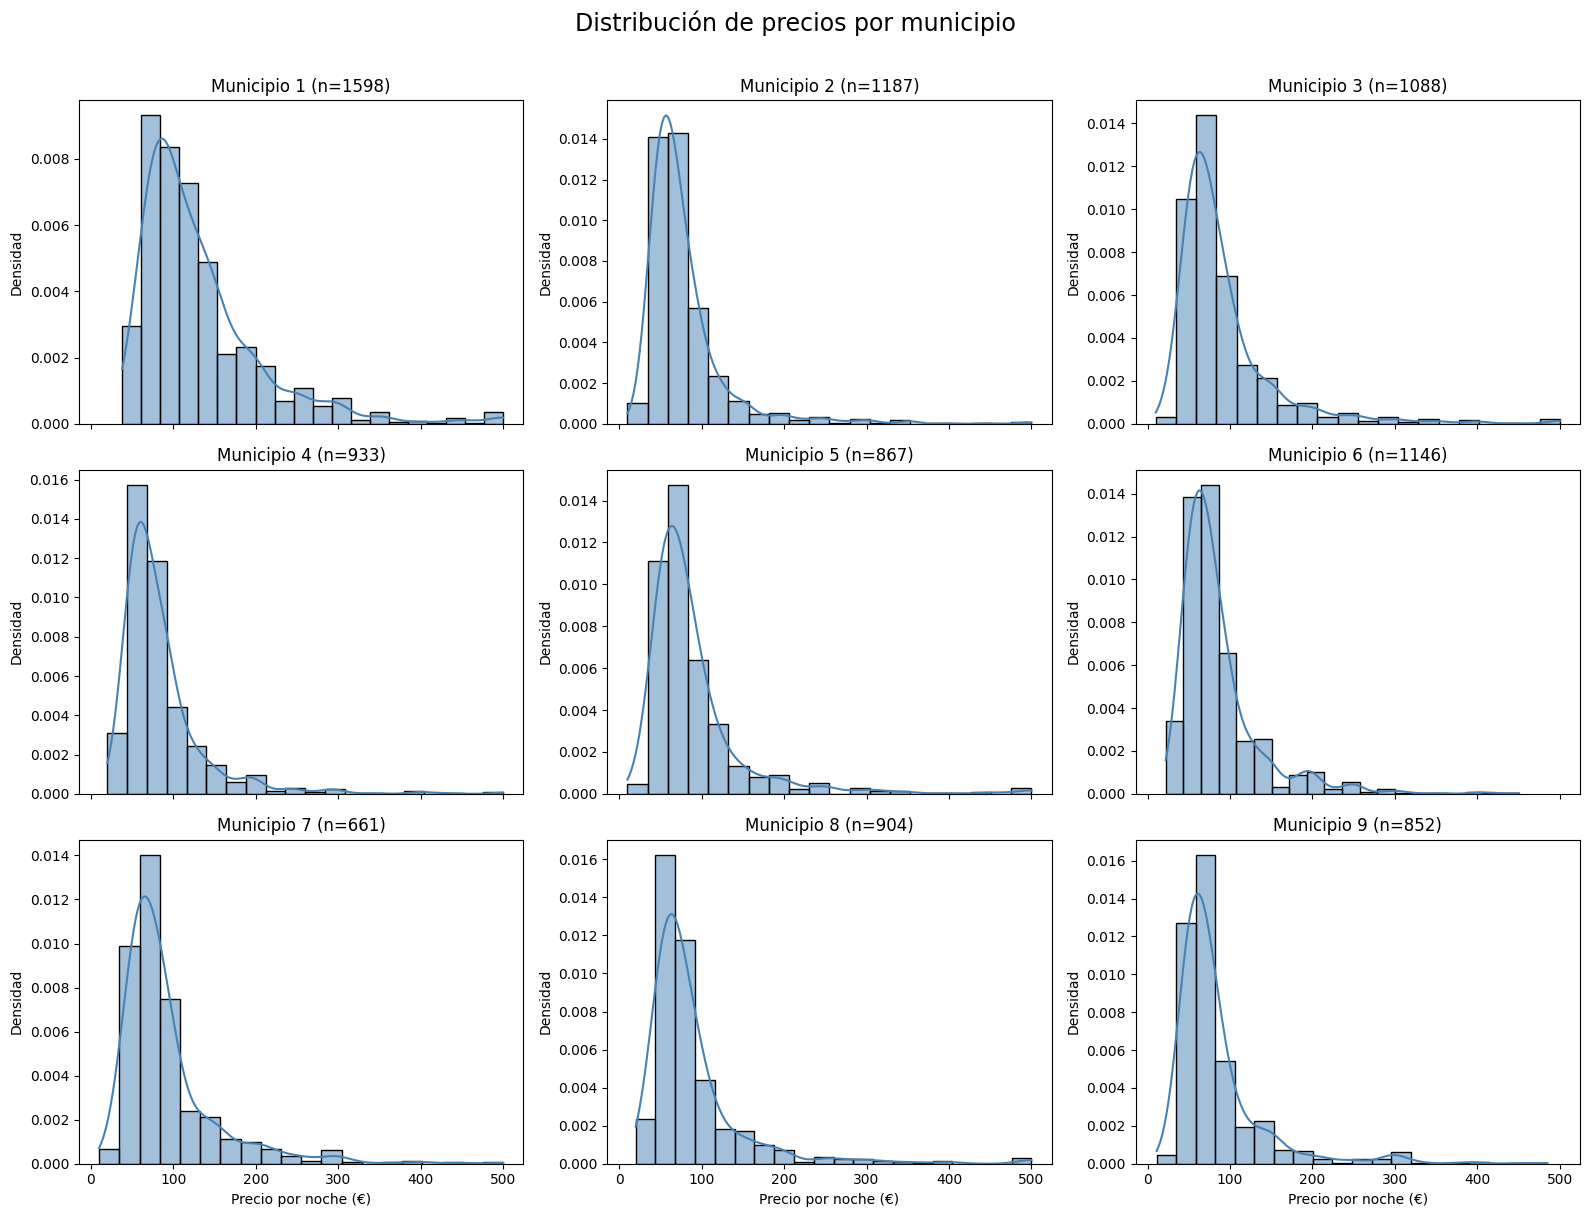

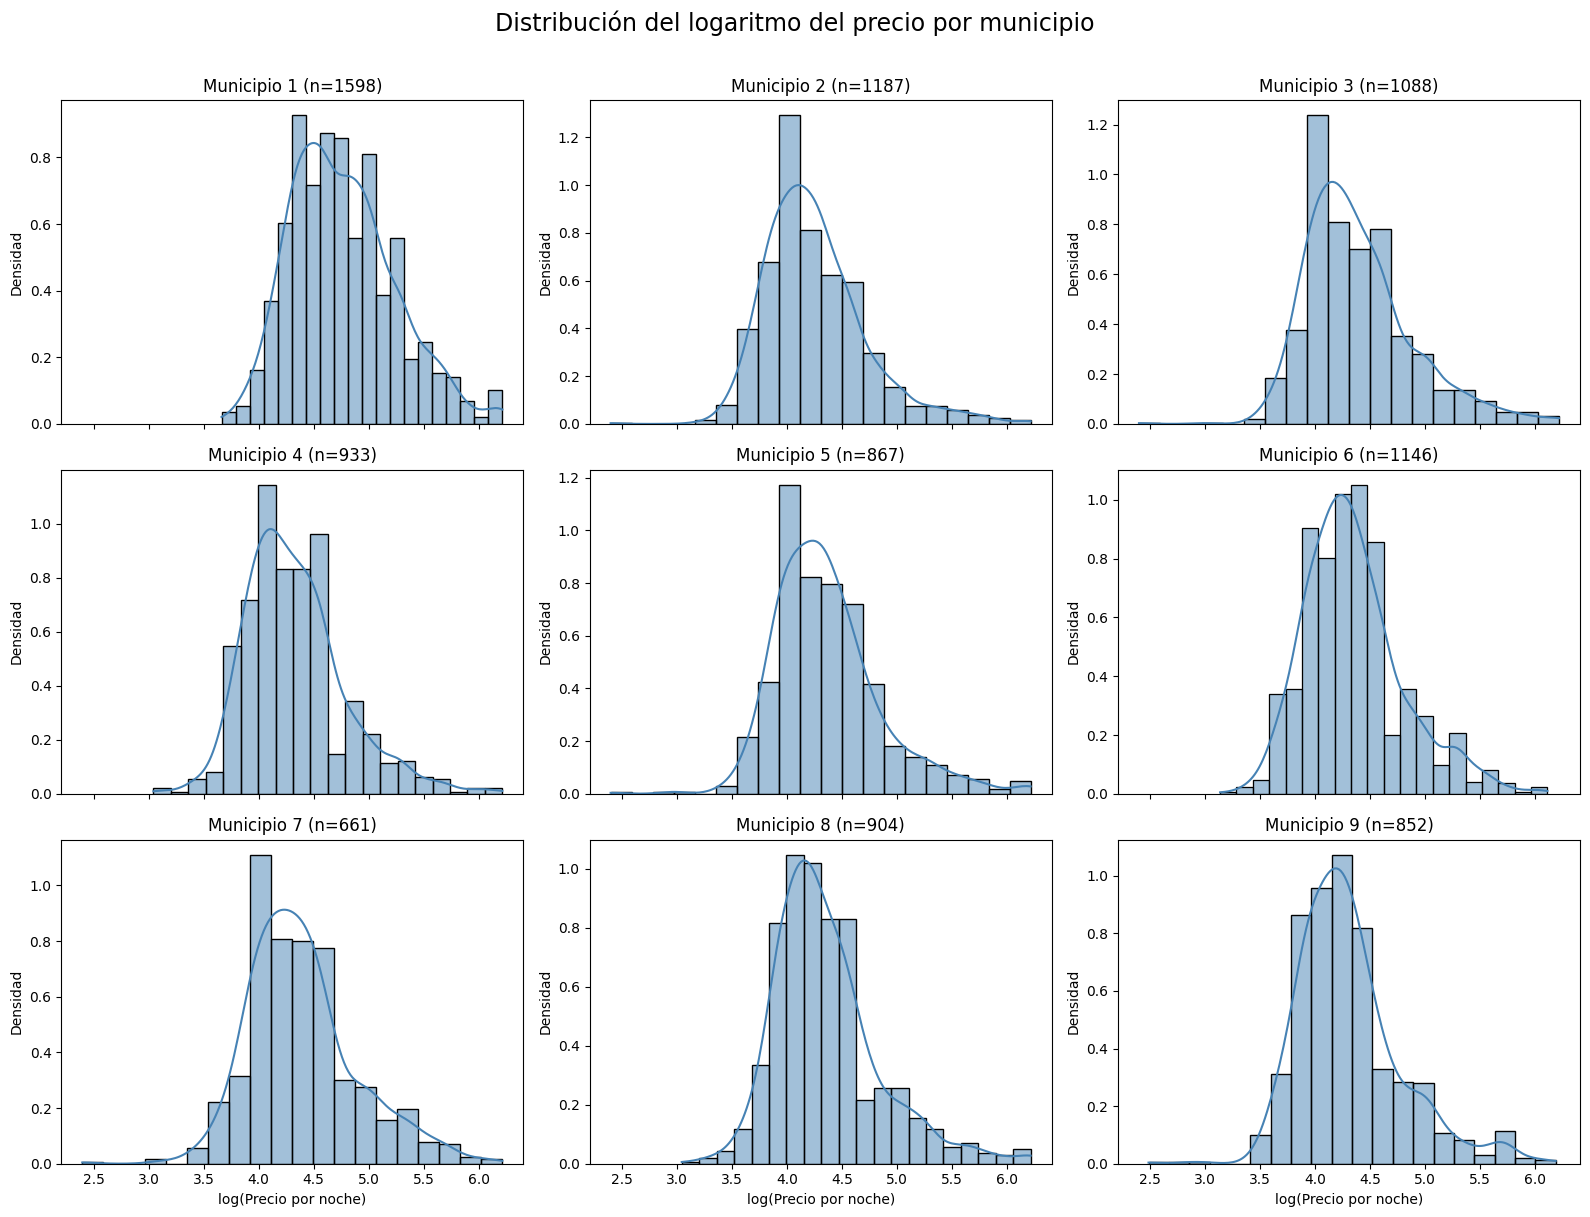

In [43]:
# @title
from math import ceil

# Preparación de los datos
data = df_raw[
    ["neighbourhood_cleansed", "daily_price"]
].dropna().copy()

# El logaritmo requiere precios positivos
data = data[data["daily_price"] > 0]

# Excluir el 1% de precios más altos solo para visualizar
limite = data["daily_price"].quantile(0.99)
data = data[data["daily_price"] <= limite].copy()

# Transformación logarítmica
data["log_daily_price"] = np.log1p(data["daily_price"])

# Municipios
municipios = sorted(data["neighbourhood_cleansed"].unique())


def plot_histogramas_por_municipio(columna, titulo, xlabel):
    n_cols = 3
    n_rows = ceil(len(municipios) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(16, 4 * n_rows),
        sharex=True
    )

    axes = np.array(axes).flatten()

    for ax, municipio in zip(axes, municipios):
        subset = data[
            data["neighbourhood_cleansed"] == municipio
        ]

        sns.histplot(
            data=subset,
            x=columna,
            bins=20,
            kde=True,
            stat="density",
            color="steelblue",
            ax=ax
        )

        ax.set_title(
            f"Municipio {municipio} (n={len(subset)})"
        )
        ax.set_xlabel(xlabel)
        ax.set_ylabel("Densidad")

    # Eliminar ejes sobrantes
    for ax in axes[len(municipios):]:
        ax.remove()

    fig.suptitle(titulo, fontsize=17, y=1.01)
    plt.tight_layout()
    plt.show()


# Figura 1: precios originales
plot_histogramas_por_municipio(
    "daily_price",
    "Distribución de precios por municipio",
    "Precio por noche (€)"
)

# Figura 2: logaritmo de los precios
plot_histogramas_por_municipio(
    "log_daily_price",
    "Distribución del logaritmo del precio por municipio",
    "log(Precio por noche)"
)

Vemos que el precio tiene una distribución aproximada lognormal

In [44]:
df_raw["log_daily_price"] = np.log1p(df_raw["daily_price"]) # log(1+x) para que sea positivo

### 1) Identificación e información del anfitrión

- ❌**`host_response_rate`**: Porcentaje de consultas respondidas por el anfitrión.
- ✅**`host_is_superhost`**: Indica si el anfitrión tiene la categoría Superhost. `1 = sí`, `0 = no`.
- ✅**`host_total_listings_count`**: Cantidad total de propiedades publicadas por el anfitrión.
- ❌**`host_identity_verified`**: Indica si Airbnb verificó la identidad del anfitrión. `1 = sí`, `0 = no`.

In [45]:
INFO_HOST = ["host_is_superhost", "host_total_listings_count"]

### 2) Ubicación del alojamiento




- ✅**`neighbourhood_cleansed`**: Barrio o zona de la ciudad donde se encuentra el alojamiento, según la clasificación normalizada de Airbnb.
- ✅**`latitude`**: Latitud geográfica del alojamiento.
- ✅**`longitude`**: Longitud geográfica del alojamiento.

Justificación: el código postal aporta información geográfica parcialmente redundante con el barrio y las coordenadas. Se prioriza conservar la ubicación exacta mediante latitud y longitud, además del barrio como variable categórica.

Estas variables permiten representar tanto diferencias entre zonas como variaciones espaciales dentro de ellas.

In [46]:
UBICACION = ["neighbourhood_cleansed", "latitude", "longitude"]

### 3) Características del alojamiento


- ❌room_type`**: Tipo de alojamiento ofrecido. En este dataset se consideran únicamente apartamentos o viviendas completas.
- ✅**`accommodates`**: Cantidad máxima de huéspedes que puede alojar la propiedad.
- ✅**`bathrooms`**: Cantidad de baños del alojamiento.
- ✅**`bedrooms`**: Cantidad de dormitorios del alojamiento.
- ✅**`beds`**: Cantidad de camas disponibles.
- ✅**`bed_type`**: Tipo de cama ofrecida, representado mediante categorías.


In [47]:
display(df_raw["room_type"].value_counts(normalize=True))
display(df_raw["bed_type"].value_counts())

,proportion
room_type,
Entire home/apt,1.0


,count
bed_type,
1,9091
2,205
3,17
4,5
5,4


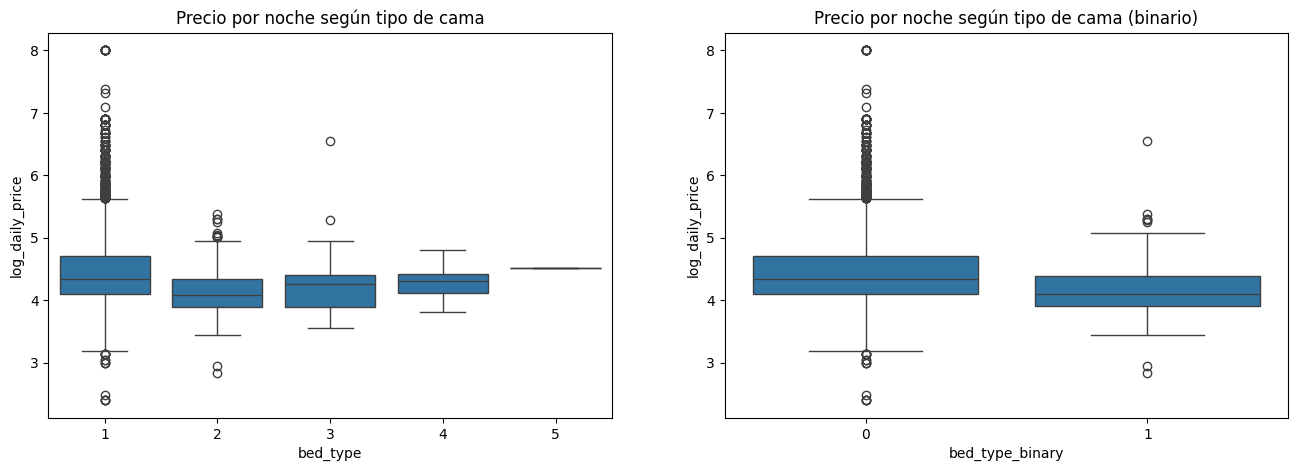

In [48]:
# Genero box plots de los tipos de camas
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df_raw, x="bed_type", y="log_daily_price", ax=axes[0])
axes[0].set_title("Precio por noche según tipo de cama")

df_raw["bed_type_binary"] = (df_raw["bed_type"] >= 2).astype(int)
sns.boxplot(data=df_raw, x="bed_type_binary", y="log_daily_price", ax=axes[1])
axes[1].set_title("Precio por noche según tipo de cama (binario)")
plt.show()

Variable eliminadas:
- `room_type`: El dataset contiene únicamente propiedades completas, por lo que esta variable no presenta variabilidad y no permite diferenciar observaciones.

In [49]:
ALOJAMIENTO = ["accommodates", "bathrooms", "bedrooms", "beds", "bed_type"]


### 4) Precios y condiciones de reserva





- ❌**`security_deposit`**: Depósito de garantía solicitado por el anfitrión.
- ❌**`cleaning_fee`**: Cargo adicional por limpieza del alojamiento.
- ✅**`guests_included`**: Cantidad de huéspedes incluidos en el precio base.
- ❌**`extra_people`**: Cargo adicional por cada huésped extra.
- ✅**`minimum_nights`**: Cantidad mínima de noches exigida para reservar el alojamiento.

In [50]:
CONDS_RESERVA = ["guests_included", "minimum_nights"]

Justificación: estas variables forman parte de la estructura de precios definida por el anfitrión y pueden estar estrechamente relacionadas con el propio daily_price.

Se decide excluirlas para que el modelo estime el precio por noche principalmente a partir de características del alojamiento, y no de otros importes fijados simultáneamente por el anfitrión.

Esto no implica necesariamente que constituyan data leakage, sino que responde al enfoque elegido para el problema de predicción.

Se conservan minimum_nights y guests_included, ya que describen condiciones de reserva que pueden influir en el precio base.

### 5) Disponibilidad




- ❌**`availability_30`**: Cantidad de días disponibles para reservar durante los próximos 30 días.
- ❌**`availability_60`**: Cantidad de días disponibles para reservar durante los próximos 60 días.
- ❌**`availability_90`**: Cantidad de días disponibles para reservar durante los próximos 90 días.
- ✅**`availability_365`**: Cantidad de días disponibles para reservar durante los próximos 365 días.

In [51]:
DISPONIBILIDAD = ["availability_365"]

Justificación: las cuatro variables describen la disponibilidad del mismo alojamiento utilizando diferentes horizontes temporales, por lo que presentan información parcialmente superpuesta.

Para reducir la redundancia y la cantidad de variables, se decide conservar únicamente `availability_365`, que resume la disponibilidadlo largo de un período más amplio.

Cabe destacar que la disponibilidad no equivale directamente a la ocupación, ya que los días no disponibles pueden corresponder a reservas o bloqueos del calendario

### 6) Reseñas y evaluaciones

- ✅**`number_of_reviews`**: Cantidad total de reseñas recibidas por el alojamiento.
- ✅**`review_scores_rating`**: Puntuación general del alojamiento otorgada por los huéspedes (escala de 0 a 100).
- ❌**`review_scores_accuracy`**: Puntuación sobre qué tan precisa es la descripción del alojamiento (0 a 10).
- ❌**`review_scores_cleanliness`**: Puntuación de limpieza del alojamiento (0 a 10).
- ❌**`review_scores_checkin`**: Puntuación del proceso de ingreso o check-in (0 a 10).
- ❌**`review_scores_communication`**: Puntuación de la comunicación con el anfitrión (0 a 10).
- ❌**`review_scores_location`**: Puntuación de la ubicación del alojamiento (0 a 10).
- ❌**`review_scores_value`**: Puntuación de la relación calidad-precio del alojamiento (0 a 10).



Justificación: para simplificar el modelo, se utiliza la puntuación general como indicador resumido de la satisfacción de los huéspedes, evitando incorporar todas las evaluaciones individuales, que pueden presentar correlaciones importantes.

Se elimina específicamente review_scores_value porque mide la percepción de la relación calidad-precio, la cual depende parcialmente del precio que se intenta predecir.

In [52]:
REVIEWS = ["number_of_reviews", "review_scores_rating"]

### 7) Políticas y condiciones adicionales ❌

- **`instant_bookable`**: Indica si el alojamiento permite realizar reservas instantáneas sin aprobación previa del anfitrión.
- **`cancellation_policy`**: Tipo de política de cancelación establecida por el anfitrión.


Se eliminan todas estas, ya que no depende del alojamiento en si, sino del anfitrion

### 8) Servicios y comodidades

Las siguientes variables son binarias: `1 = disponible/permitido`, `0 = no disponible/no permitido`. ✅

- **`TV`**: Disponibilidad de televisión.
- **`WiFi`**: Disponibilidad de conexión inalámbrica a Internet.
- **`Air_Condition`**: Disponibilidad de aire acondicionado.
- **`Wheelchair_accessible`**: Accesibilidad para personas que utilizan silla de ruedas.
- **`Kitchen`**: Disponibilidad de cocina.
- **`Breakfast`**: Desayuno incluido u ofrecido.
- **`Elevator`**: Disponibilidad de ascensor.
- **`Heating`**: Disponibilidad de calefacción.
- **`Washer`**: Disponibilidad de lavarropas.
- **`Iron`**: Disponibilidad de plancha.
- **`Host_greets_you`**: Indica si el anfitrión recibe personalmente a los huéspedes.
- **`Paid_parking_on_premises`**: Disponibilidad de estacionamiento pago dentro de la propiedad.
- **`Luggage_dropoff_allowed`**: Posibilidad de dejar el equipaje antes del check-in o después del check-out.
- **`Long_term_stays_allowed`**: Indica si se permiten estadías prolongadas.
- **`Doorman`**: Disponibilidad de portero o servicio de recepción.
- **`Pets_allowed`**: Indica si se permiten mascotas.
- **`Smoking_allowed`**: Indica si se permite fumar.
- **`Suitable_for_events`**: Indica si el alojamiento permite organizar eventos.
- **`24_hour_check_in`**: Disponibilidad de ingreso al alojamiento durante las 24 horas.

In [53]:
COMODIDADES = [
    "Air_Condition", "Wheelchair_accessible", "Kitchen",
    "Breakfast", "Elevator", "Heating", "Washer", "Iron",
    "Host_greets_you", "Paid_parking_on_premises", "Luggage_dropoff_allowed",
    "Long_term_stays_allowed", "Doorman", "Pets_allowed", "Smoking_allowed",
    "Suitable_for_events", "24_hour_check_in"
]

tabla_frecuencias(df_raw, COMODIDADES)

NameError: name 'tabla_frecuencias' is not defined

## SELECCION DE VARIABLES

In [ ]:
FEATURES = (
    INFO_HOST + UBICACION + ALOJAMIENTO + CONDS_RESERVA +
    DISPONIBILIDAD + REVIEWS + COMODIDADES
)

TARGET = "log_daily_price"

df = df_raw[FEATURES + ["daily_price"] + [TARGET]].copy()

df.to_csv("data/intermedio/milan_airbnb_select_vars.csv", index=False)


In [ ]:
df.info()

In [ ]:
variables_numericas = list(set(FEATURES) - set(COMODIDADES)) + [TARGET]

df[variables_numericas].describe()

## 1.4 valores atípicos (outliers)

### Precio

In [ ]:
df["daily_price"].value_counts().sort_index(ascending=False).head(10)

El precio máximo salta desde 1600 directamente a 3000. Pareciera que 3000 es un precio máximo. Los eliminamos

In [ ]:
df_price_cleaned = df[df["daily_price"] < 3000].copy()

In [ ]:
n_cols = 3
n_rows = int(np.ceil(len(variables_numericas) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows)
)

axes = axes.flatten()

for ax, col in zip(axes, variables_numericas):

    sns.boxplot(
        data=df_price_cleaned,
        y=col,
        ax=ax
    )

    ax.set_title(col)
    ax.set_ylabel("")

for ax in axes[len(variables_numericas):]:
    ax.remove()

fig.suptitle(
    "Detección de valores atípicos mediante boxplots",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [ ]:
def resumen_outliers(df, columnas):
    resultados = []

    for col in columnas:
        x = df[col].dropna()

        q1 = x.quantile(0.25)
        q3 = x.quantile(0.75)
        iqr = q3 - q1

        lim_inf = q1 - 1.5 * iqr
        lim_sup = q3 + 1.5 * iqr

        # IQR = 0: criterio no informativo
        if iqr == 0:
            n_outliers = np.nan
            porcentaje = np.nan
        else:
            outliers = (x < lim_inf) | (x > lim_sup)
            n_outliers = outliers.sum()
            porcentaje = outliers.mean() * 100

        resultados.append({
            "variable": col,
            "Q1": q1,
            "Q3": q3,
            "IQR": iqr,
            "lim_inf": lim_inf,
            "lim_sup": lim_sup,
            "n_outliers": n_outliers,
            "porcentaje": porcentaje
        })

    return pd.DataFrame(resultados).set_index("variable")


resumen = resumen_outliers(df_price_cleaned, variables_numericas)

display(resumen.round(2))

Algo extraño pasa con los baños

### Analisis de los baños

In [ ]:
df["bathrooms"].value_counts(dropna=False).sort_index()

In [ ]:
df_raw.loc[
    df_raw["bathrooms"],
    ["bathrooms", "bedrooms", "accommodates"]
].sample(20, random_state=42)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Bathrooms vs log_daily_price
sns.stripplot(
    data=df,
    x="bathrooms",
    y="log_daily_price",
    jitter=0.25,
    alpha=0.15,
    size=3,
    ax=axes[0]
)

# Agregar medianas por cantidad de baños
sns.pointplot(
    data=df,
    x="bathrooms",
    y="log_daily_price",
    estimator=np.median,
    errorbar=None,
    color="red",
    markers="o",
    linestyles="-",
    ax=axes[0]
)

axes[0].set_title("Bathrooms vs Log Daily Price")
axes[0].set_xlabel("Bathrooms")
axes[0].set_ylabel("Log Daily Price")


# 2. Bathrooms vs Bedrooms
sns.stripplot(
    data=df,
    x="bathrooms",
    y="bedrooms",
    jitter=0.25,
    alpha=0.15,
    size=3,
    ax=axes[1]
)

axes[1].set_title("Bathrooms vs Bedrooms")
axes[1].set_xlabel("Bathrooms")
axes[1].set_ylabel("Bedrooms")

plt.tight_layout()
plt.show()

Observando estos datos decidimos eliminar los registros que no tienen baños entre 2 y 11 ya que presentan una relación bastante lineal y más de 12 hay muy pocos datos.

In [ ]:
df_bathrooms_cleaned = df_price_cleaned[df_price_cleaned["bathrooms"].between(2, 11)].copy()

Resulta que salta el precio de 1600 a 3000. Pareciera ser 3000 un precio máximo.

In [ ]:
from scipy.stats import zscore

col = "log_daily_price"

# Calcular Z-scores
z = pd.Series(
    zscore(df_bathrooms_cleaned[col], nan_policy="omit"),
    index=df_bathrooms_cleaned.index
)

# Identificar valores atípicos
outliers = df_bathrooms_cleaned.loc[z.abs() > 3]

print(f"Outliers: {len(outliers)}")
print(f"Porcentaje: {len(outliers) / df_bathrooms_cleaned[col].notna().sum() * 100:.2f}%")

# Estadísticos de los valores atípicos
display(outliers[col].describe())

In [ ]:
display(
    outliers["daily_price"]
    .value_counts()
    .head(15)
)

## 1.5 Análisis exploratorio

In [ ]:
df = df_bathrooms_cleaned.copy()

### Matriz de correlación

In [ ]:
# Matriz de correlaciones de Pearson
corr = df[variables_numericas].corr(method="pearson")

# Ocultar triángulo superior
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(13, 11))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.1,
    square=True,
    cbar_kws={"label": "Correlación de Pearson"}
)

plt.title("Matriz de correlaciones", fontsize=16)
plt.tight_layout()
plt.show()


### Análisis geográfico

In [ ]:
data = df[
    ["latitude", "longitude", "neighbourhood_cleansed", "daily_price"]
].copy()

# Convertir municipios a categorías
data["municipio"] = data["neighbourhood_cleansed"].astype(str)

# Estadísticas por municipio
municipios = (
    data.groupby("municipio")
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        precio_medio=("daily_price", "mean"),
    )
    .reset_index()
)

# Gráfico
fig, ax = plt.subplots(figsize=(12, 10))

sns.scatterplot(
    data=data,
    x="longitude",
    y="latitude",
    hue="municipio",
    palette="tab10",
    s=12,
    alpha=0.5,
    linewidth=0,
    ax=ax,
)

# Etiquetas con municipio y precio mediano
for _, row in municipios.iterrows():
    ax.annotate(
        f"Municipio {row['municipio']}\n"
        f"{row['precio_medio']:.0f} €",
        xy=(row["longitude"], row["latitude"]),
        ha="center",
        va="center",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.4",
            facecolor="white",
            edgecolor="black",
            alpha=0.9,
        ),
    )

ax.set_title(
    "Distribución de alojamientos por municipio en Milán",
    fontsize=15,
)
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")

ax.legend(
    title="Municipio",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()


In [ ]:
# Preparación
data = df[
    ["latitude", "longitude", "neighbourhood_cleansed", "log_daily_price"]
].dropna().copy()

# Ordenar municipios según el log-precio mediano
orden = (
    data.groupby("neighbourhood_cleansed")["log_daily_price"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=data,
    x="neighbourhood_cleansed",
    y="log_daily_price",
    order=orden,
    hue="neighbourhood_cleansed",
    palette="tab10",
    showfliers=False,
    legend=False,
)

plt.title("Distribución del log-precio por municipio")
plt.xlabel("Municipio")
plt.ylabel("log(daily_price)")
plt.tight_layout()
plt.show()

In [ ]:
target = "log_daily_price"

# Excluir los targets
features = df.columns.drop(["daily_price", "log_daily_price"])

# Configuración de la grilla
n_cols = 4
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, 4 * n_rows),
    sharey=True
)

axes = axes.flatten()

for ax, col in zip(axes, features):

    # Variables categóricas o discretas con pocos valores
    es_categorica = (
        not pd.api.types.is_numeric_dtype(df[col])
        or col == "neighbourhood_cleansed"
        or df[col].nunique() <= 12
    )

    if es_categorica:
        sns.boxplot(
            data=df,
            x=col,
            y=target,
            showfliers=False,
            ax=ax
        )
        ax.tick_params(axis="x", rotation=45)

    else:
        sns.scatterplot(
            data=df,
            x=col,
            y=target,
            alpha=0.2,
            s=12,
            ax=ax
        )

    ax.set_title(col, fontsize=12)
    ax.set_xlabel("")
    ax.set_ylabel("Log(precio por noche)")

# Eliminar ejes sobrantes
for ax in axes[len(features):]:
    ax.remove()

fig.suptitle(
    "Relación entre las variables predictoras y el log-precio",
    fontsize=18,
    y=1.01
)

plt.tight_layout()
plt.show()

In [ ]:
# Antes de tomar la muestra cambiamos el nombre de la variable 24_hour_check_in
# porque al tener un número adelante no lo toma bien en la formula para el OLS.
df.rename(columns={"24_hour_check_in": "check_in_24_hour"}, inplace=True)

# Guardamos el dataset base para la regresión lineal
df.to_csv("data/base/milan_airbnb_completo.csv", index=False)